# Rayleigh MIMO detector benchmark

The default 4×4 BPSK run compares MAP, MMSE, QR-SIC, Partial MAP, and trained PMAP-Net on the same received samples. The SNR sweep includes 5 dB.

Set `PMAPNET_CHECKPOINT` to a checkpoint path or leave it empty to pick the newest compatible checkpoint in `02_colab_output`. Set `TEST_PMAPNET = False` to run the analytical detectors and export training layer CSVs.

In [6]:
# Colab setup. For a local run, use the project checkout and set OUTPUT_ROOT below.
import os
from pathlib import Path
import subprocess
import sys

from google.colab import drive

repo = Path("/content/EE_MIMO_PROJECT")
if (repo / ".git").exists():
    subprocess.run(["git", "pull", "--ff-only", "origin", "main"], cwd=repo, check=True)
else:
    subprocess.run([
        "git", "clone", "--depth", "1", "--branch", "main",
        "https://github.com/billlllllllly/EE_MIMO_PROJECT.git", str(repo),
    ], check=True)

os.chdir(repo)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
%pip install -r requirements.txt
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# import models
from importlib import reload
import sys

from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

# Refresh the module if this kernel imported it before the Git update.
if "src.models.PMAPnet" in sys.modules:
    reload(sys.modules["src.models.PMAPnet"])
from src.models.PMAPnet import PMAPNet

In [8]:
# MIMO and checkpoint settings
from pathlib import Path

import torch
from src.channel.rayleighfading import rayleighfading

BLOCKS = 1000
SYMBOLS_PER_CHANNEL = 10
NT = 4
NR = 4
SNR_DB = sorted([5, *range(0, 21, 2)])
MODULATION = "BPSK"

OUTPUT_ROOT = Path("/content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output")
TEST_PMAPNET = True
PMAPNET_CHECKPOINT = "pmapnet_20261127_174015_054984/pmapnet_bpsk.pt"  # Absolute path or relative to OUTPUT_ROOT


def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)


qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
symbol_qpsk = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])
bpsk = torch.tensor([-1, 1], dtype=torch.complex128) / 2**0.5
symbol_bpsk = torch.tensor([[0], [1]])

In [9]:
# PMAP-Net adapter for the BER testbench
class PMAPNetDetector(partialMAP):
    def __init__(self, checkpoint):
        super().__init__(verbose=False)
        self.network = PMAPNet(**checkpoint["model_kwargs"])
        self.network.load_state_dict(checkpoint["model_state_dict"])
        self.network.eval()
        self.num_tx = checkpoint["model_kwargs"]["num_tx"]

    def updateCSI(self, csi):
        num_rx, num_tx = csi.shape
        if num_tx != self.num_tx or num_rx < num_tx:
            raise ValueError(f"PMAP-Net requires {self.num_tx} transmit streams and at least as many receivers.")
        super().updateCSI(csi)
        if next(self.network.parameters()).device != self.Q.device:
            self.network.to(self.Q.device)

    @torch.inference_mode()
    def detectSequence(self, received):
        received = torch.as_tensor(received, dtype=self.Q.dtype, device=self.Q.device)
        z = received @ self.Q.conj()
        constellation = self.possibleTXSymbols.to(z.device)
        features = []
        for row in range(self.NT):
            products = (self.R[row, row:, None] * constellation).reshape(1, -1)
            # Match the training feature order: z, R times constellation, then split real/imag.
            values = torch.cat((z[:, row:row + 1], products.expand(z.shape[0], -1)), dim=1)
            features.append(torch.cat((values.real, values.imag), dim=1).float())

        local_llrs = self.network(features)
        llrs = z.real.new_zeros((z.shape[0], self.NT, self.B))
        for row in reversed(range(self.NT)):
            llrs[:, row:] += local_llrs[row].reshape(z.shape[0], self.NT - row, self.B)
        return (llrs < 0).long().transpose(0, 1)


def load_pmapnet_checkpoint(path, output_root, num_tx, modulation, symbols, bit_labels):
    if path:
        candidates = [output_root / path]
    else:
        pattern = f"pmapnet_*/pmapnet_{modulation.lower()}.pt"
        candidates = sorted(output_root.glob(pattern), reverse=True)
    if not candidates:
        raise FileNotFoundError(f"No PMAP-Net checkpoint found in {output_root}. Set PMAPNET_CHECKPOINT.")

    for candidate in candidates:
        state = torch.load(candidate, map_location="cpu", weights_only=True)
        kwargs = state["model_kwargs"]
        saved_symbols = state["constellation"]
        if (
            kwargs["num_tx"] == num_tx
            and kwargs["modulation_order"] == symbols.numel()
            and saved_symbols.shape == symbols.shape
            and torch.allclose(saved_symbols.to(symbols), symbols)
            and torch.equal(state["bit_labels"], bit_labels)
        ):
            return candidate, state

    raise ValueError(f"No selected checkpoint matches {num_tx}-stream {modulation} and its bit labels.")

Testing PMAP-Net checkpoint /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/pmapnet_20261127_174015_054984/pmapnet_bpsk.pt
Trained on /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK/5dB
running channel number 0
running channel number 10
running channel number 20
running channel number 30
running channel number 40
running channel number 50
running channel number 60
running channel number 70
running channel number 80
running channel number 90
running channel number 100
running channel number 110
running channel number 120
running channel number 130
running channel number 140
running channel number 150
running channel number 160
running channel number 170
running channel number 180
running channel number 190
running channel number 200
running channel number 210
running channel number 220
running channel number 230
running channel number 240
running channel number 250
running channel number 260
running channel number 270
running channel number 280
running

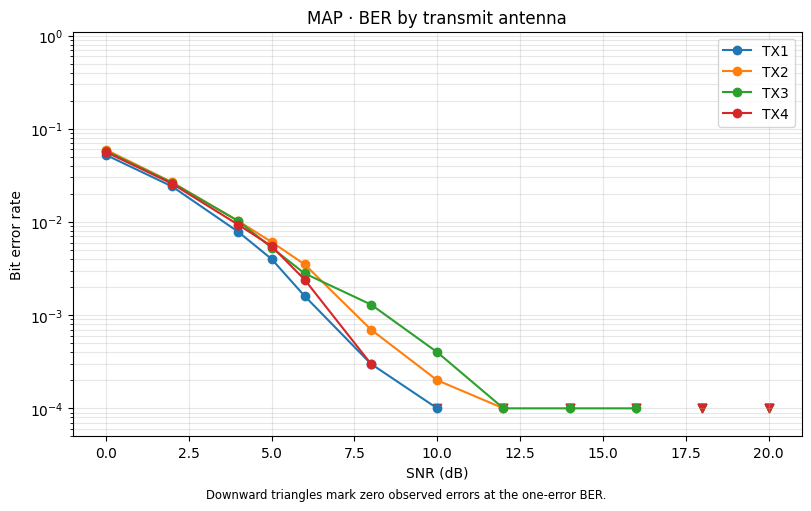

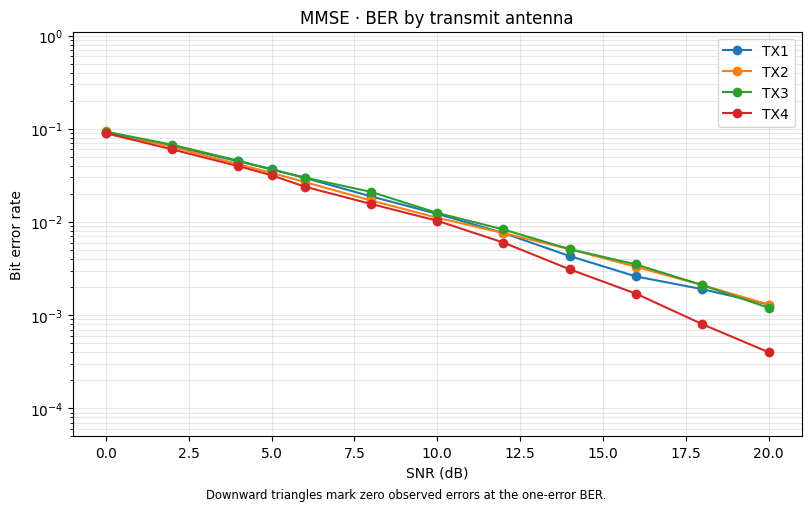

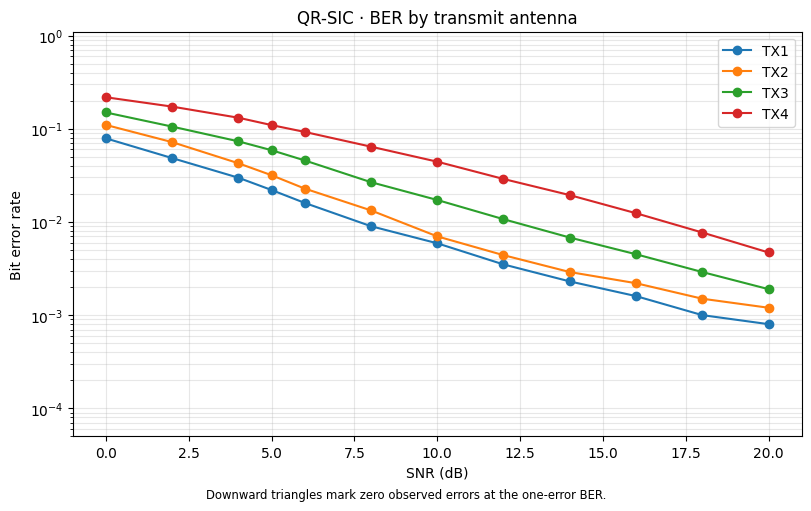

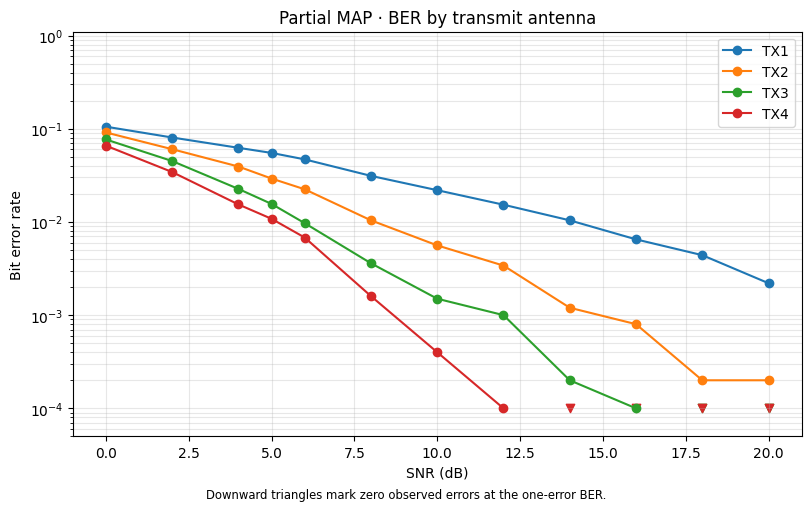

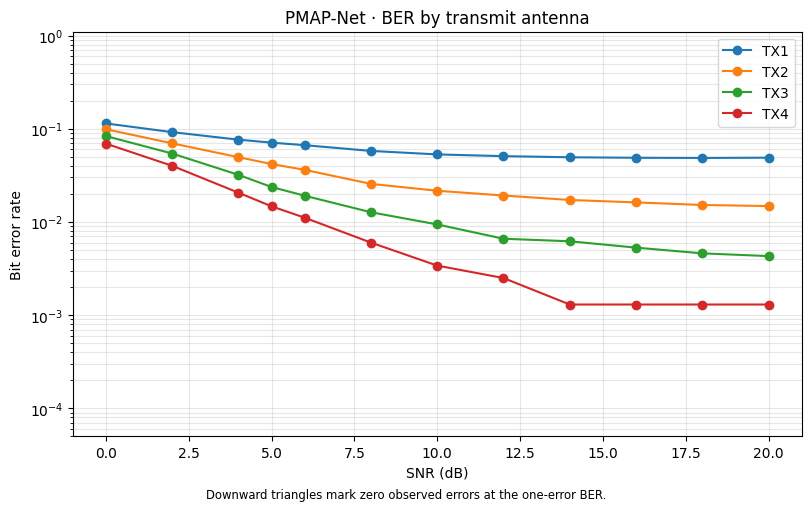

40,000 bits per SNR
SNR (dB)            MAP          MMSE        QR-SIC   Partial MAP      PMAP-Net
       0        0.05647       0.09123        0.1389       0.08472       0.09135
       2        0.02565       0.06423       0.09957       0.05502       0.06395
       4       0.009375       0.04285        0.0692       0.03492        0.0446
       5       0.005225       0.03465       0.05547       0.02765       0.03778
       6       0.002575       0.02757       0.04423       0.02145       0.03325
       8        0.00065        0.0181        0.0283        0.0117       0.02552
      10       0.000175       0.01153        0.0186       0.00735       0.02185
      12          5e-05      0.007375       0.01188       0.00495       0.01978
      14        2.5e-05        0.0044       0.00785       0.00295       0.01852
      16        2.5e-05      0.002775      0.005175       0.00185        0.0179
      18              0      0.001725      0.003275       0.00115       0.01742
      20            

In [10]:
from datetime import datetime
from hashlib import sha256
from pathlib import Path
from tempfile import mkdtemp
from uuid import uuid4
from zoneinfo import ZoneInfo

from src.channel.testbench import Testbench


class PartialMAPBySNR(partialMAP):
    def updateNoiseVar(self, noiseVar):
        super().updateNoiseVar(noiseVar)
        self.csv_log_dir = self.log_dirs_by_variance[self.noiseVar]


# Use a fresh directory because Partial MAP appends rows to its CSV files.
pmap_log_dir = Path(mkdtemp(prefix="rayleigh_pmap_"))
pmap = PartialMAPBySNR(verbose=False)
models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": pmap,
}

symbols, bit_labels = (qpsk, symbol_qpsk) if MODULATION == "QPSK" else (bpsk, symbol_bpsk)
checkpoint_tag = None
if TEST_PMAPNET:
    checkpoint_path, checkpoint = load_pmapnet_checkpoint(
        PMAPNET_CHECKPOINT, OUTPUT_ROOT, NT, MODULATION, symbols, bit_labels
    )
    models["PMAP-Net"] = PMAPNetDetector(checkpoint)
    checkpoint_tag = sha256(checkpoint_path.read_bytes()).hexdigest()[:12]
    print(f"Testing PMAP-Net checkpoint {checkpoint_path}")
    training_data = checkpoint.get("settings", {}).get("layer_data")
    if training_data:
        print(f"Trained on {training_data}")

bench = Testbench(models, symbols, bit_labels, SYMBOLS_PER_CHANNEL, SNR_DB)
# The testbench sets this variance before each detection batch.
pmap.log_dirs_by_variance = {
    variance: pmap_log_dir / f"{str(snr).removesuffix('.0')}dB"
    for snr, variance in zip(bench.snr_db, bench.noise_variances)
}
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
run_id = uuid4().hex
config_folder = f"rayleigh_{NR}_by_{NT}_{MODULATION}"
ERROR_CSV = pmap_log_dir / "rayleigh_bit_errors.csv"
cumulative = None
ber, bits_per_snr = bench.run(csi, csv_path=ERROR_CSV, plot_antenna_ber=True)
completed_at = datetime.now(ZoneInfo("Asia/Taipei")).isoformat(timespec="seconds")

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

In [11]:
# Save error counts and layer CSVs to Drive.
from src.simulation.ber_history import save_ber_history

out_dir = OUTPUT_ROOT / config_folder
if checkpoint_tag is not None:
    # Keep benchmark exports apart from training data and runs with other weights.
    out_dir = OUTPUT_ROOT / f"{config_folder}_pmapnet" / checkpoint_tag
cumulative = save_ber_history(ERROR_CSV, out_dir, run_id, completed_at)
print(f"Saved layer CSVs, cumulative error counts, and simulation logs to {out_dir}")

Saved layer CSVs, cumulative error counts, and simulation logs to /content/drive/MyDrive/EE_MIMO_PROJECT/02_colab_output/rayleigh_4_by_4_BPSK_pmapnet/535689e8e982


Downward triangles: zero observed errors, shown at one error divided by the transmitted bit count.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

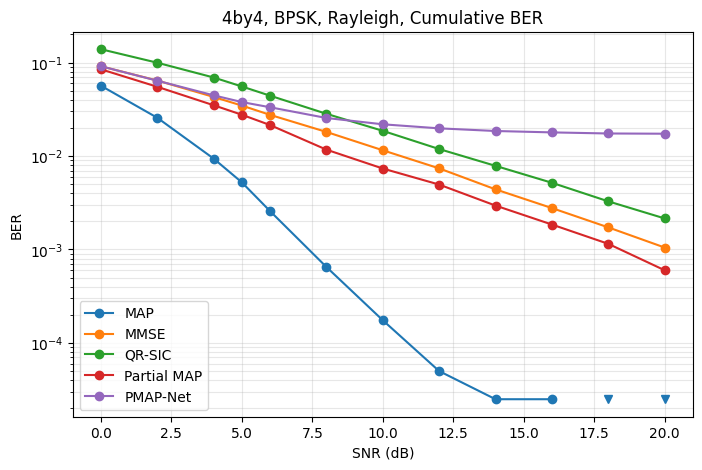

In [12]:
import matplotlib.pyplot as plt
import numpy as np

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    if cumulative is None:
        points = np.asarray(ber[:, j])
        totals = np.full(len(snr_db), bits_per_snr)
    else:
        rows = [cumulative[snr, name] for snr in snr_db]
        points = np.array([row["ber"] for row in rows])
        totals = np.array([row["total_bits_transmitted"] for row in rows])
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            1 / totals[zero],
            "v",
            color=line.get_color(),
        )

scope = "Cumulative BER" if cumulative is not None else "Run BER"
TITLE = f"{NT}by{NR}, {MODULATION}, Rayleigh, {scope}"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at one error divided by the transmitted bit count.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
try:
    from google.colab import files
except ImportError:
    pass
else:
    download_csv = ERROR_CSV if cumulative is None else ERROR_CSV.with_name("cumulative_rayleigh_bit_errors.csv")
    files.download(str(download_csv))
    files.download(f'{TITLE}.png')

plt.show()